In [10]:
import torch
from torch import nn
import numpy as np
import cv2
import matplotlib.pyplot as plt

from sift import (
    SIFTParams, 
    build_octaves, 
    build_dog, 
    find_scale_space_extrema
)

from util import (
    draw_octaves_grid, 
    assert_octaves, 
    read_octaves, 
    read_keypoints, 
    draw_keypoints,
    assert_keypoints
)

In [11]:
# read the same way as in course to reuse numerical tests

image = cv2.imread("data/mysh1.jpg")

rows, cols = image.shape[:2]
image = cv2.resize(image, (cols // 8, rows // 8), interpolation=cv2.INTER_AREA)
image = cv2.cvtColor(image, cv2.COLOR_BGRA2GRAY)
image = torch.from_numpy(image).to(torch.float32) / 255.0
image = image.unsqueeze(0)

# F.to_pil_image(image)

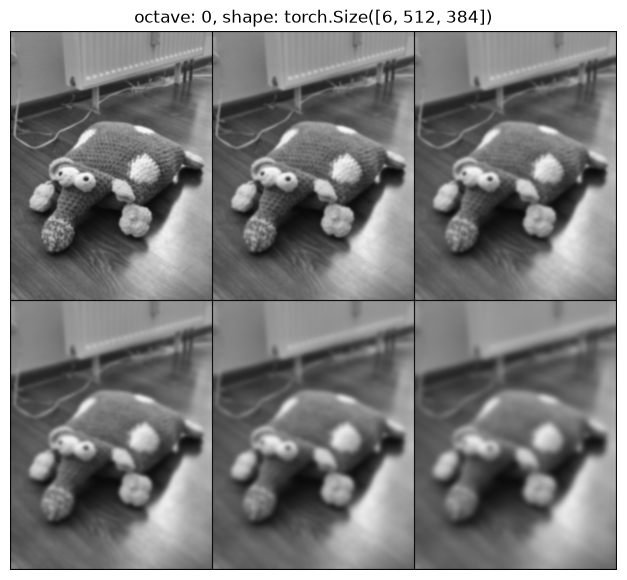

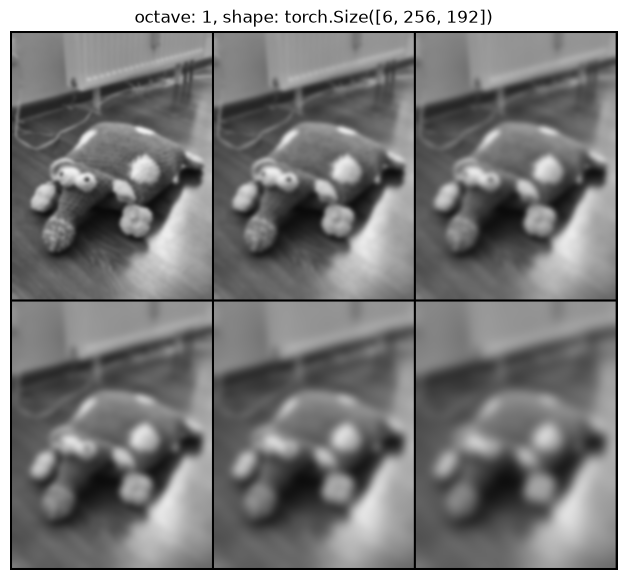

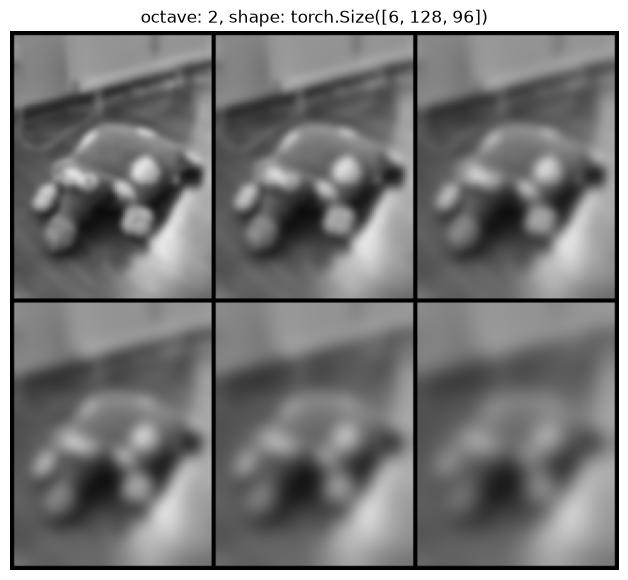

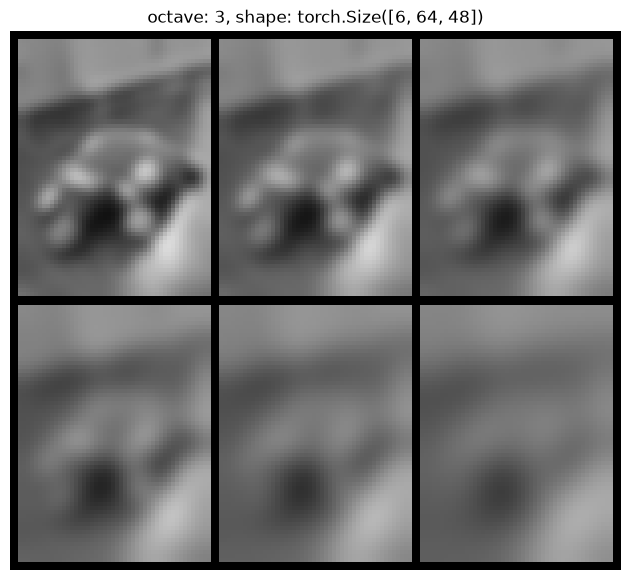

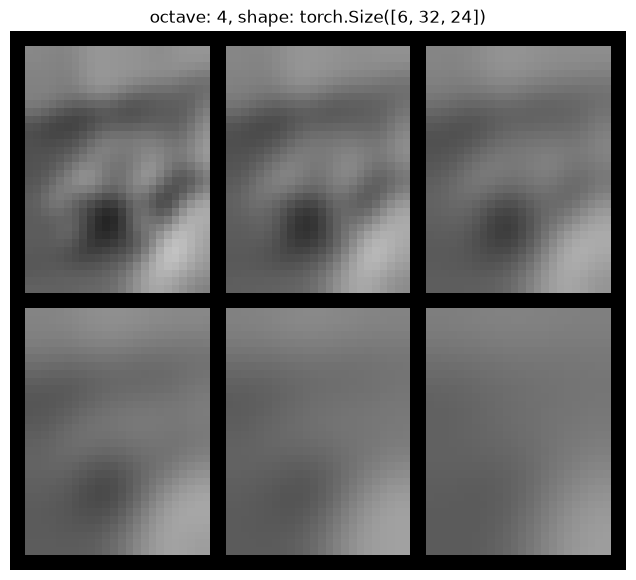

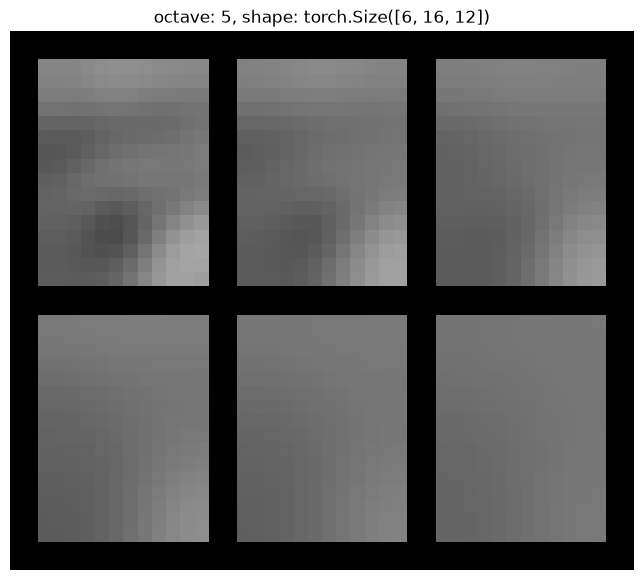

In [12]:
params = SIFTParams()
params.upscale_first = False

octaves = build_octaves(image, params)

draw_octaves_grid(octaves)

In [13]:
ref_octaves = read_octaves('data/test_steps_data/step1_octaves.yml.gz')

assert_octaves(octaves, ref_octaves)

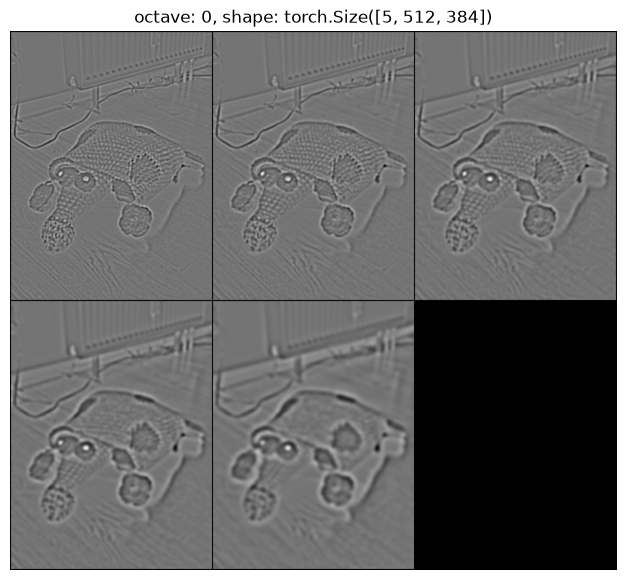

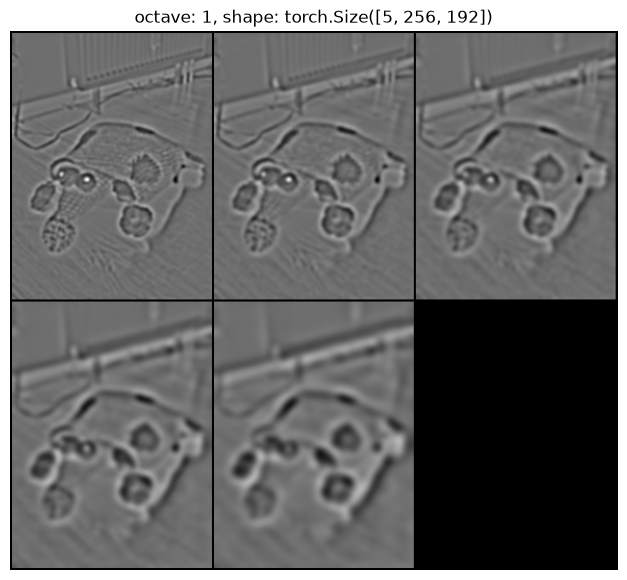

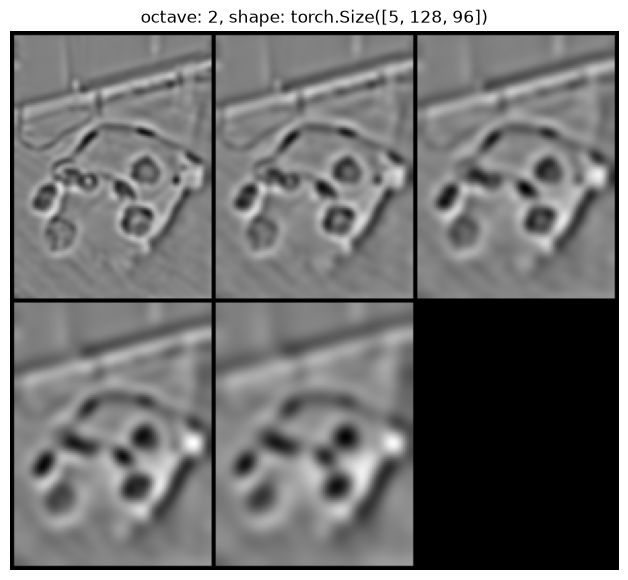

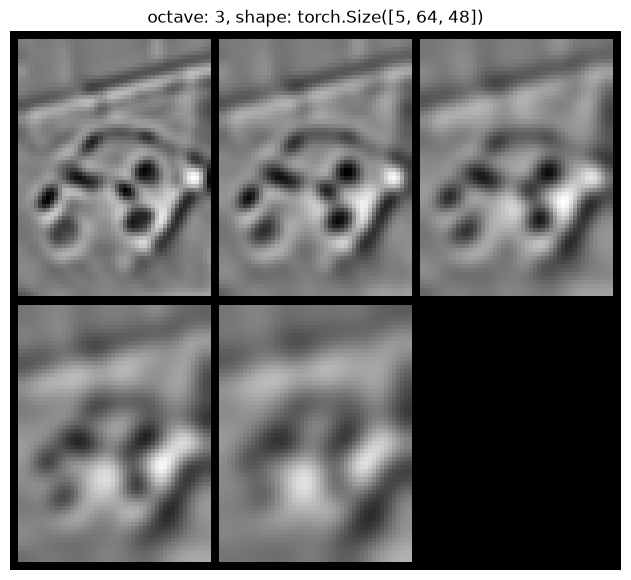

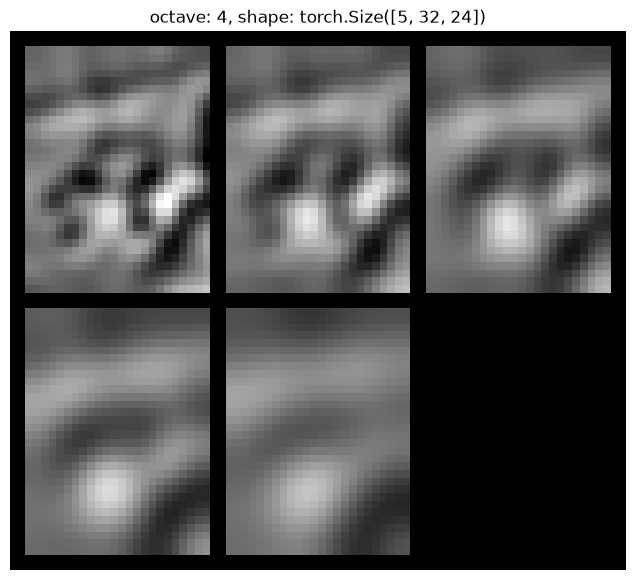

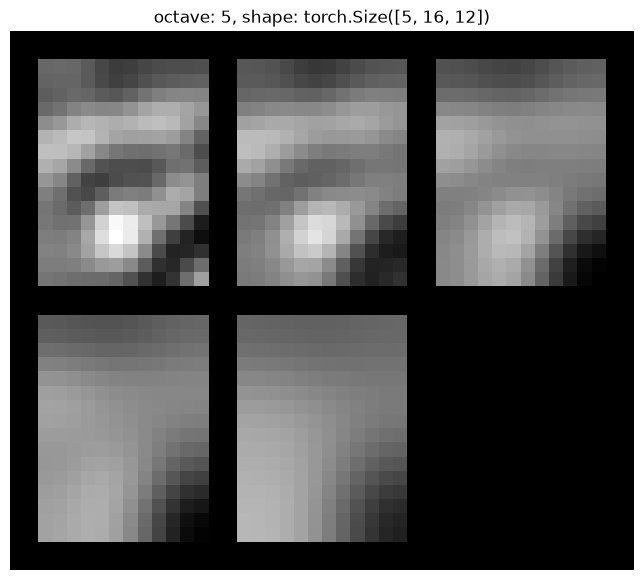

In [14]:
dog = build_dog(octaves)

draw_octaves_grid(dog, normalize=True)

In [15]:
ref_dog = read_octaves("data/test_steps_data/step2_dog.yml.gz")

assert_octaves(dog, ref_dog)

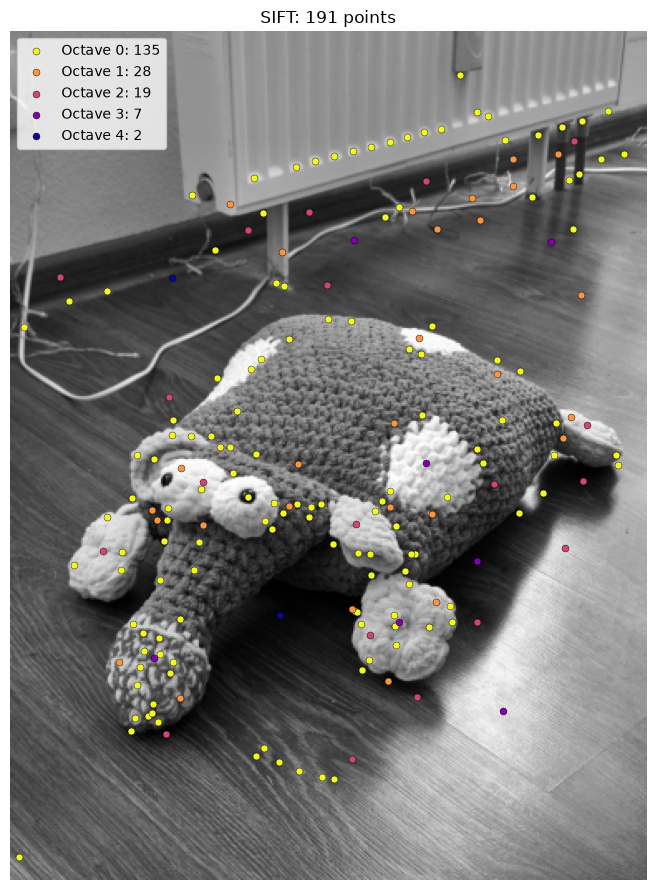

In [16]:
keypoints = find_scale_space_extrema(dog, params)
len(keypoints)

draw_keypoints(image, keypoints)

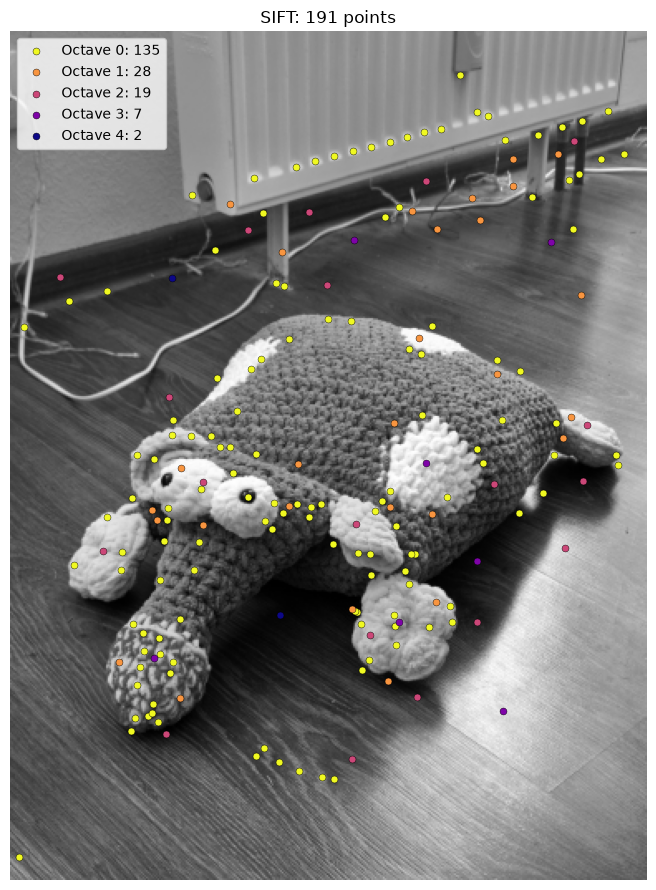

In [17]:
ref_keypoints = read_keypoints("data/test_steps_data/step3_extrema.yml.gz")

draw_keypoints(image, ref_keypoints)

In [18]:
response_key = lambda kp: kp.response
assert_keypoints(sorted(keypoints, key=response_key), sorted(ref_keypoints, key=response_key))